In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/images/Youtube05-Shakira.csv
/kaggle/input/images/Youtube03-LMFAO.csv
/kaggle/input/images/Youtube02-KatyPerry.csv
/kaggle/input/images/Youtube01-Psy.csv
/kaggle/input/images/Youtube04-Eminem.csv
/kaggle/input/images/youtube-spam-collection-v1/Youtube05-Shakira.csv
/kaggle/input/images/youtube-spam-collection-v1/Youtube03-LMFAO.csv
/kaggle/input/images/youtube-spam-collection-v1/Youtube02-KatyPerry.csv
/kaggle/input/images/youtube-spam-collection-v1/Youtube01-Psy.csv
/kaggle/input/images/youtube-spam-collection-v1/Youtube04-Eminem.csv


In [2]:
import os
import glob

path = "/kaggle/input/images/youtube-spam-collection-v1/"
all_files = glob.glob(os.path.join(path, "*.csv"))
dfs = []

for filename in all_files:
    frame = pd.read_csv(filename, index_col=None, header=0)
    dfs.append(frame)

In [3]:
df = pd.concat(dfs, axis=0, ignore_index=True)

In [4]:
df.head()

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS
0,z13lgffb5w3ddx1ul22qy1wxspy5cpkz504,dharma pal,2015-05-29T02:30:18.971000,Nice song﻿,0
1,z123dbgb0mqjfxbtz22ucjc5jvzcv3ykj,Tiza Arellano,2015-05-29T00:14:48.748000,I love song ﻿,0
2,z12quxxp2vutflkxv04cihggzt2azl34pms0k,Prìñçeśś Âliś Łøvê Dømíñø Mâđiś™ ﻿,2015-05-28T21:00:08.607000,I love song ﻿,0
3,z12icv3ysqvlwth2c23eddlykyqut5z1h,Eric Gonzalez,2015-05-28T20:47:12.193000,"860,000,000 lets make it first female to reach...",0
4,z133stly3kete3tly22petvwdpmghrlli,Analena López,2015-05-28T17:08:29.827000,shakira is best for worldcup﻿,0


In [5]:
df.shape

(1956, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1956 entries, 0 to 1955
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   COMMENT_ID  1956 non-null   object
 1   AUTHOR      1956 non-null   object
 2   DATE        1711 non-null   object
 3   CONTENT     1956 non-null   object
 4   CLASS       1956 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 76.5+ KB


In [7]:
df = df[["CONTENT", "CLASS"]]

<Axes: ylabel='CLASS'>

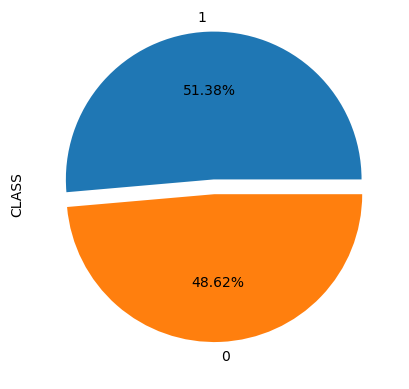

In [8]:
df["CLASS"].value_counts().plot(kind="pie", autopct="%.2f%%", explode=[0.1, 0])

In [9]:
X = df["CONTENT"]
y = df["CLASS"]

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_scaled = cv.fit_transform(X)

In [11]:
from sklearn.model_selection import  train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2)

In [12]:
from sklearn.naive_bayes import BernoulliNB

nb = BernoulliNB()
nb.fit(X_train, y_train)

BernoulliNB()

In [13]:
nb.score(X_test, y_test)

0.875

In [14]:
sample = "Follow me: https://example.com"
test = cv.transform([sample]).toarray()
nb.predict(test)

array([1])